<a href="https://colab.research.google.com/github/Aditi21-prog/Exoplanet-finder/blob/main/1_0_Exoplanet_Finder_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("hello space")


hello space


In [ ]:
!pip install lightkurve

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 75.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 60.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 96.3 MB/s  0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11429 sha256=19853e4c1c0d44011d8c603f06aacd18a5c705c64893a921fbf7bb5f3ca5166a
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/289ba063a9ae0ba3189c6914e992722575868b2cb41100401b
  Created wheel for memoization: filename=memoization-0.4.0-py3-none-any.whl size=50537 sha256=3af772ee44a4313263d5ffb59a59f1fc13d4d63f46a1cad86d3b9c9f7696d792
  Stored in directory: /root/.cache/pip/wheels/5c/ef/65/c51178502ccdadab909ffa9339a9a897019

In [ ]:
import lightkurve, pandas, torch
print("everything works")

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


everything works


In [ ]:
import pandas as pd

url = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query="
       "select+kepid,tce_plnt_num,tce_period,tce_time0bk,tce_duration,tce_depth,av_training_set"
       "+from+q1_q17_dr24_tce&format=csv")
tce = pd.read_csv(url)
print(len(tce))
print(tce.head())

20367
     kepid  tce_plnt_num  tce_period  tce_time0bk  tce_duration  tce_depth  \
0  1162345             2    0.831850      132.227         2.392      6.092   
1  1292087             2    1.095240      132.133         2.122     34.530   
2  1293031             2    0.719273      132.227         1.521     29.680   
3  1162345             3    0.831833      131.919         2.181     27.100   
4  1164109             1  622.408000      162.256        12.010    161.300   

  av_training_set  
0             AFP  
1             UNK  
2             UNK  
3             AFP  
4             UNK  


In [ ]:
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()
tce["planet"] = (tce.av_training_set == "PC").astype(int)
print(len(tce))
print(tce.planet.mean())

15737
0.22876024655271018


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# first cut: 10% of stars become the test pile
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
trainval_idx, test_idx = next(gss.split(tce, groups=tce.kepid))
trainval = tce.iloc[trainval_idx]
test = tce.iloc[test_idx]

# second cut: split the rest into train and validation
gss2 = GroupShuffleSplit(n_splits=1, test_size=1/9, random_state=42)
train_idx, val_idx = next(gss2.split(trainval, groups=trainval.kepid))
train = trainval.iloc[train_idx]
val = trainval.iloc[val_idx]

print(len(train), len(val), len(test))
print(set(train.kepid) & set(test.kepid))

12624 1569 1544
set()


In [ ]:
import lightkurve as lk

search = lk.search_lightcurve("KIC 11442793", mission="Kepler", cadence="long")
print(len(search))
print(search)

14
SearchResult containing 14 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 01 2009 Kepler    1800 kplr011442793      0.0
  1 Kepler Quarter 02 2009 Kepler    1800 kplr011442793      0.0
  2 Kepler Quarter 03 2009 Kepler    1800 kplr011442793      0.0
  3 Kepler Quarter 04 2010 Kepler    1800 kplr011442793      0.0
  4 Kepler Quarter 05 2010 Kepler    1800 kplr011442793      0.0
  5 Kepler Quarter 06 2010 Kepler    1800 kplr011442793      0.0
  6 Kepler Quarter 07 2010 Kepler    1800 kplr011442793      0.0
  7 Kepler Quarter 09 2011 Kepler    1800 kplr011442793      0.0
  8 Kepler Quarter 10 2011 Kepler    1800 kplr011442793      0.0
  9 Kepler Quarter 11 2012 Kepler    1800 kplr011442793      0.0
 10 Kepler Quarter 13 2012 Kepler    1800 kplr011442793      0.0
 11 Kepler Quarter 14 2012 Kepler    1800 kp

In [ ]:
lc = search.download_all().stitch().remove_nans()
print(len(lc))
print(lc.time.value[:3])

51503
[131.51243946 131.53287376 131.55330797]


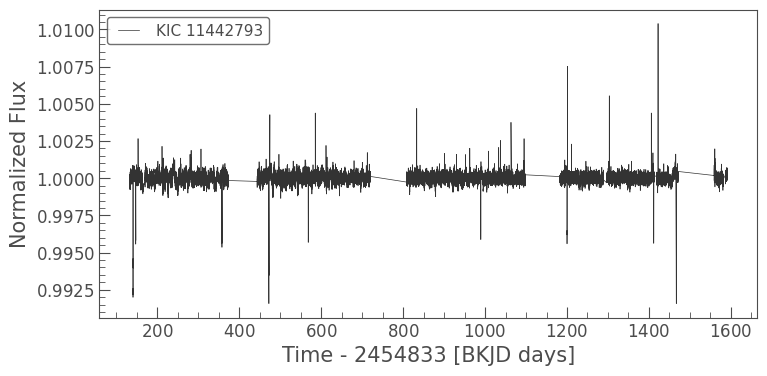

In [ ]:
lc.plot();

In [ ]:
k90 = tce[tce.kepid == 11442793]
print(k90)

          kepid  tce_plnt_num  tce_period  tce_time0bk  tce_duration  \
17694  11442793             1     331.603       140.48         14.49   

       tce_depth av_training_set  planet  
17694     8365.0              PC       1  


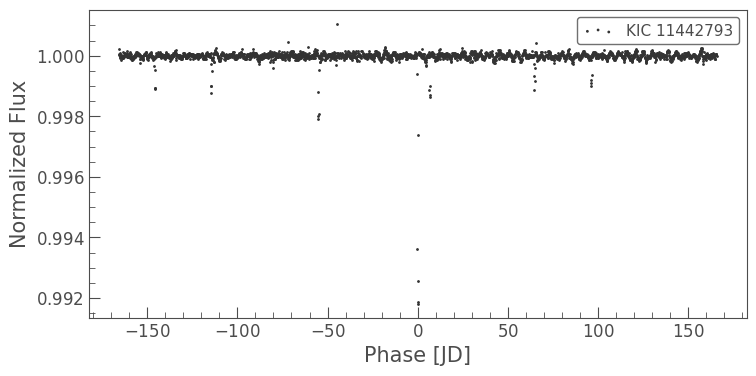

In [ ]:
row = k90.iloc[0]
period = row.tce_period
t0 = row.tce_time0bk
dur = row.tce_duration / 24   # table gives hours, we need days

mask = lc.create_transit_mask(period=period, transit_time=t0, duration=2 * dur)
flat = lc.flatten(window_length=401, mask=mask)
folded = flat.fold(period=period, epoch_time=t0)
folded.bin(time_bin_size=dur / 5).scatter();

In [ ]:
import numpy as np

def binned(phase, flux, lo, hi, n):
    edges = np.linspace(lo, hi, n + 1)
    idx = np.digitize(phase, edges) - 1
    out = np.array([np.median(flux[idx == i]) if (idx == i).any() else np.nan
                    for i in range(n)])
    out[np.isnan(out)] = np.nanmedian(out)
    return out

def norm(v):
    v = v - np.median(v)
    d = abs(v.min())
    return v / d if d > 0 else v

def make_views(lc, period, t0, duration_hr):
    dur = duration_hr / 24
    mask = lc.create_transit_mask(period=period, transit_time=t0, duration=2 * dur)
    flat = lc.flatten(window_length=401, mask=mask)
    t, f = flat.time.value, flat.flux.value
    phase = (t - t0 + period / 2) % period - period / 2
    glob = binned(phase, f, -period / 2, period / 2, 2001)
    loc = binned(phase, f, -4 * dur, 4 * dur, 201)
    depth = 1 - np.median(f[np.abs(phase) < dur / 2])
    return norm(glob), norm(loc), depth

print("functions ready")

functions ready


global view length: 2001
local view length: 201
depth: 0.00764799074058975


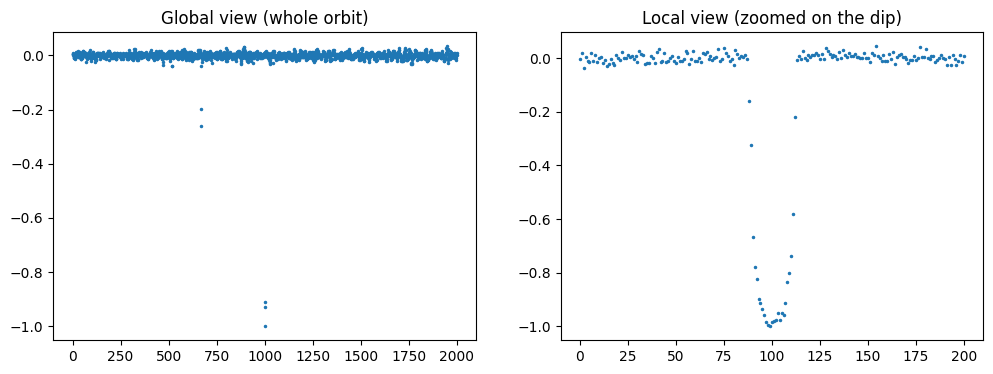

In [ ]:
import matplotlib.pyplot as plt

row = k90.iloc[0]
g, l, depth = make_views(lc, row.tce_period, row.tce_time0bk, row.tce_duration)

print("global view length:", len(g))
print("local view length:", len(l))
print("depth:", depth)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(g, ".", markersize=3)
axes[0].set_title("Global view (whole orbit)")
axes[1].plot(l, ".", markersize=3)
axes[1].set_title("Local view (zoomed on the dip)")
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/drive/MyDrive/exoplanet/lc', exist_ok=True)
print("folder ready")

Mounted at /content/drive
folder ready


In [ ]:
import numpy as np, lightkurve as lk, os

LC_DIR = '/content/drive/MyDrive/exoplanet/lc'

def get_lc(kepid):
    path = f"{LC_DIR}/{kepid}.npz"
    if os.path.exists(path):
        d = np.load(path)
        return lk.LightCurve(time=d["t"], flux=d["f"])
    try:
        res = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler", cadence="long")
        if len(res) == 0:
            return None
        lc = res.download_all().stitch().remove_nans()
    except Exception:
        return None
    np.savez(path, t=lc.time.value, f=lc.flux.value)
    return lc

def build(df, name):
    G, L, D, Y = [], [], [], []
    for i, (_, r) in enumerate(df.iterrows()):
        lc = get_lc(int(r.kepid))
        if lc is None:
            continue
        try:
            g, l, d = make_views(lc, r.tce_period, r.tce_time0bk, r.tce_duration)
        except Exception:
            continue
        G.append(g); L.append(l); D.append(d); Y.append(r.planet)
        if i % 20 == 0:
            print(name, i, "of", len(df))
    np.savez(f"/content/drive/MyDrive/exoplanet/{name}.npz",
             G=np.array(G), L=np.array(L), D=np.array(D), Y=np.array(Y))
    print(name, "done:", len(Y), "examples")

print("recipe ready")

recipe ready


In [ ]:
small_train = train[train.kepid.isin(train.kepid.unique()[:140])]
small_val = val[val.kepid.isin(val.kepid.unique()[:30])]
small_test = test[test.kepid.isin(test.kepid.unique()[:30])]
print(len(small_train), len(small_val), len(small_test))

220 52 45


In [ ]:
build(small_val, "val")
build(small_test, "test")
build(small_train, "train")

val 0 of 52
val 20 of 52
val 40 of 52
val done: 49 examples
test 0 of 45
test 20 of 45
test 40 of 45
test done: 45 examples
train 0 of 220
train 20 of 220
train 40 of 220
train 60 of 220
train 80 of 220
train 100 of 220
train 120 of 220
train 140 of 220
train 180 of 220
train 200 of 220
train done: 207 examples


In [ ]:
import numpy as np

tr = np.load('/content/drive/MyDrive/exoplanet/train.npz')
va = np.load('/content/drive/MyDrive/exoplanet/val.npz')
te = np.load('/content/drive/MyDrive/exoplanet/test.npz')

print("train planets:", tr["Y"].sum(), "of", len(tr["Y"]))
print("val planets:", va["Y"].sum(), "of", len(va["Y"]))
print("test planets:", te["Y"].sum(), "of", len(te["Y"]))
print("shapes:", tr["G"].shape, tr["L"].shape)

train planets: 36 of 207
val planets: 7 of 49
test planets: 15 of 45
shapes: (207, 2001) (207, 201)


In [ ]:
def get_features(df):
    rows = []
    for _, r in df.iterrows():
        lc = get_lc(int(r.kepid))
        if lc is None:
            continue
        try:
            make_views(lc, r.tce_period, r.tce_time0bk, r.tce_duration)
        except Exception:
            continue
        rows.append((r.tce_period, r.tce_duration))
    return np.array(rows)

Ftr = get_features(small_train)
Fva = get_features(small_val)
Fte = get_features(small_test)
print(Ftr.shape, Fva.shape, Fte.shape)

(207, 2) (49, 2) (45, 2)


In [ ]:
Xtr = np.column_stack([Ftr, tr["D"]])
Xte = np.column_stack([Fte, te["D"]])

base = HistGradientBoostingClassifier(random_state=42).fit(Xtr, tr["Y"])
probs = base.predict_proba(Xte)[:, 1]
print("baseline test AUC:", roc_auc_score(te["Y"], probs))

baseline test AUC: 0.9355555555555556


In [ ]:
print("train planets:", tr["Y"].sum(), "of", len(tr["Y"]))
print("val planets:  ", va["Y"].sum(), "of", len(va["Y"]))
print("test planets: ", te["Y"].sum(), "of", len(te["Y"]))
print("shapes:", tr["G"].shape, tr["L"].shape)

train planets: 36 of 207
val planets:   7 of 49
test planets:  15 of 45
shapes: (207, 2001) (207, 201)


In [ ]:
import torch, torch.nn as nn
from sklearn.metrics import roc_auc_score

torch.manual_seed(42)

def branch(n_blocks):
    layers, ch = [], 1
    for i in range(n_blocks):
        out = 16 * 2**i
        layers += [nn.Conv1d(ch, out, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2)]
        ch = out
    return nn.Sequential(*layers, nn.Flatten())

class PlanetNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.glob = branch(4)   # 2001 -> 125 long, 128 channels
        self.loc = branch(3)    # 201 -> 25 long, 64 channels
        self.head = nn.Sequential(
            nn.Linear(128 * 125 + 64 * 25, 128), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(128, 1))
    def forward(self, g, l):
        z = torch.cat([self.glob(g), self.loc(l)], dim=1)
        return self.head(z).squeeze(1)

def to_t(d):
    return (torch.tensor(d["G"], dtype=torch.float32).unsqueeze(1),
            torch.tensor(d["L"], dtype=torch.float32).unsqueeze(1),
            torch.tensor(d["Y"], dtype=torch.float32))

Gtr, Ltr, Ytr = to_t(tr)
Gva, Lva, Yva = to_t(va)
Gte, Lte, Yte = to_t(te)
print("network ready", Gtr.shape, Ltr.shape)

network ready torch.Size([207, 1, 2001]) torch.Size([207, 1, 201])


In [ ]:
import copy
model = PlanetNet()
opt = torch.optim.Adam(model.parameters(), lr=1e-4)
loss_fn = nn.BCEWithLogitsLoss()

best_auc, best_state, wait = 0, None, 0
for epoch in range(40):
    model.train()
    perm = torch.randperm(len(Ytr))
    for i in range(0, len(perm), 32):
        b = perm[i:i+32]
        opt.zero_grad()
        loss = loss_fn(model(Gtr[b], Ltr[b]), Ytr[b])
        loss.backward()
        opt.step()
    model.eval()
    with torch.no_grad():
        vp = torch.sigmoid(model(Gva, Lva)).numpy()
    auc = roc_auc_score(Yva.numpy(), vp)
    print(f"epoch {epoch+1}  loss {loss.item():.3f}  val AUC {auc:.3f}")
    if auc > best_auc:
        best_auc, best_state, wait = auc, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= 8:
            break
model.load_state_dict(best_state)
print("best val AUC:", best_auc)

epoch 1  loss 0.483  val AUC 0.650
epoch 2  loss 0.385  val AUC 0.670
epoch 3  loss 0.846  val AUC 0.677
epoch 4  loss 0.631  val AUC 0.680
epoch 5  loss 0.286  val AUC 0.690
epoch 6  loss 0.513  val AUC 0.701
epoch 7  loss 0.688  val AUC 0.697
epoch 8  loss 0.594  val AUC 0.694
epoch 9  loss 0.653  val AUC 0.690
epoch 10  loss 0.360  val AUC 0.697
epoch 11  loss 0.347  val AUC 0.707
epoch 12  loss 0.504  val AUC 0.707
epoch 13  loss 0.520  val AUC 0.701
epoch 14  loss 0.305  val AUC 0.704
epoch 15  loss 0.565  val AUC 0.711
epoch 16  loss 0.462  val AUC 0.707
epoch 17  loss 0.267  val AUC 0.714
epoch 18  loss 0.650  val AUC 0.714
epoch 19  loss 0.334  val AUC 0.721
epoch 20  loss 0.507  val AUC 0.728
epoch 21  loss 0.303  val AUC 0.735
epoch 22  loss 0.560  val AUC 0.741
epoch 23  loss 0.348  val AUC 0.755
epoch 24  loss 0.583  val AUC 0.759
epoch 25  loss 0.409  val AUC 0.762
epoch 26  loss 0.311  val AUC 0.772
epoch 27  loss 0.397  val AUC 0.772
epoch 28  loss 0.202  val AUC 0.779
e

In [ ]:
model.eval()
with torch.no_grad():
    tp = torch.sigmoid(model(Gte, Lte)).numpy()

cnn_auc = roc_auc_score(Yte.numpy(), tp)
print("CNN test AUC:     ", cnn_auc)
print("Baseline test AUC:", roc_auc_score(te["Y"], probs))

CNN test AUC:      0.9755555555555556
Baseline test AUC: 0.9355555555555556


In [ ]:
import numpy as np, os, time

rng = np.random.RandomState(42)
stars = rng.choice(tce.kepid.unique(), size=3000, replace=False)

big_train = train[train.kepid.isin(stars)]
big_val = val[val.kepid.isin(stars)]
big_test = test[test.kepid.isin(stars)]
print(len(stars), len(big_train), len(big_val), len(big_test))

3000 3780 477 497


In [ ]:
LIMIT_HOURS = 3
start = time.time()
todo = [int(k) for k in stars if not os.path.exists(f"{LC_DIR}/{int(k)}.npz")]
print(len(todo), "stars still to download")

for n, k in enumerate(todo):
    if time.time() - start > LIMIT_HOURS * 3600:
        print("time limit reached. Run this cell again to continue.")
        break
    get_lc(k)
    if n % 25 == 0:
        print(n, "of", len(todo), f"({(time.time() - start) / 60:.0f} min)")
print("finished this run")

2930 stars still to download
0 of 2930 (0 min)
25 of 2930 (8 min)
50 of 2930 (16 min)
75 of 2930 (22 min)
100 of 2930 (30 min)
125 of 2930 (38 min)
150 of 2930 (54 min)
175 of 2930 (103 min)
200 of 2930 (117 min)
225 of 2930 (134 min)
250 of 2930 (143 min)
275 of 2930 (149 min)
300 of 2930 (154 min)
325 of 2930 (159 min)
350 of 2930 (178 min)
time limit reached. Run this cell again to continue.
finished this run


In [ ]:
stars = stars[:1000]

big_train = train[train.kepid.isin(stars)]
big_val = val[val.kepid.isin(stars)]
big_test = test[test.kepid.isin(stars)]
print(len(stars), len(big_train), len(big_val), len(big_test))

NameError: name 'stars' is not defined

In [ ]:
import numpy as np, pandas as pd, os, time
import lightkurve as lk
from sklearn.model_selection import GroupShuffleSplit
from google.colab import drive
drive.mount('/content/drive')

# label table
url = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query="
       "select+kepid,tce_plnt_num,tce_period,tce_time0bk,tce_duration,tce_depth,av_training_set"
       "+from+q1_q17_dr24_tce&format=csv")
tce = pd.read_csv(url)
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()
tce["planet"] = (tce.av_training_set == "PC").astype(int)

# same split as before (same seeds, so same piles)
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
trainval_idx, test_idx = next(gss.split(tce, groups=tce.kepid))
trainval = tce.iloc[trainval_idx]
test = tce.iloc[test_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=1/9, random_state=42)
train_idx, val_idx = next(gss2.split(trainval, groups=trainval.kepid))
train = trainval.iloc[train_idx]
val = trainval.iloc[val_idx]

# same 3000 random stars as before, then keep the first 1000
rng = np.random.RandomState(42)
stars = rng.choice(tce.kepid.unique(), size=3000, replace=False)[:1000]
big_train = train[train.kepid.isin(stars)]
big_val = val[val.kepid.isin(stars)]
big_test = test[test.kepid.isin(stars)]
print(len(stars), len(big_train), len(big_val), len(big_test))

ModuleNotFoundError: No module named 'lightkurve'

In [ ]:
!pip install lightkurve

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 46.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 48.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 64.5 MB/s  0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11429 sha256=d2a86233d68598b966ee96f5820c6e02624c7c20ab99151abdbec1da921d69fb
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/289ba063a9ae0ba3189c6914e992722575868b2cb41100401b
  Created wheel for memoization: filename=memoization-0.4.0-py3-none-any.whl size=50537 sha256=0308e6eaaf05a3ba343d6d7ac22c5bc154b0051909934305f72de0441d71fb6b
  Stored in directory: /root/.cache/pip/wheels/5c/ef/65/c51178502ccdadab909ffa9339a9a897019

In [ ]:
import numpy as np, pandas as pd, os, time
import lightkurve as lk
from sklearn.model_selection import GroupShuffleSplit
from google.colab import drive
drive.mount('/content/drive')

# label table
url = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query="
       "select+kepid,tce_plnt_num,tce_period,tce_time0bk,tce_duration,tce_depth,av_training_set"
       "+from+q1_q17_dr24_tce&format=csv")
tce = pd.read_csv(url)
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()
tce["planet"] = (tce.av_training_set == "PC").astype(int)

# same split as before (same seeds, so same piles)
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
trainval_idx, test_idx = next(gss.split(tce, groups=tce.kepid))
trainval = tce.iloc[trainval_idx]
test = tce.iloc[test_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=1/9, random_state=42)
train_idx, val_idx = next(gss2.split(trainval, groups=trainval.kepid))
train = trainval.iloc[train_idx]
val = trainval.iloc[val_idx]

# same 3000 random stars as before, then keep the first 1000
rng = np.random.RandomState(42)
stars = rng.choice(tce.kepid.unique(), size=3000, replace=False)[:1000]
big_train = train[train.kepid.isin(stars)]
big_val = val[val.kepid.isin(stars)]
big_test = test[test.kepid.isin(stars)]
print(len(stars), len(big_train), len(big_val), len(big_test))

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


Mounted at /content/drive
1000 1237 160 186


In [ ]:
import numpy as np, lightkurve as lk, os

LC_DIR = '/content/drive/MyDrive/exoplanet/lc'

def binned(phase, flux, lo, hi, n):
    edges = np.linspace(lo, hi, n + 1)
    idx = np.digitize(phase, edges) - 1
    out = np.array([np.median(flux[idx == i]) if (idx == i).any() else np.nan
                    for i in range(n)])
    out[np.isnan(out)] = np.nanmedian(out)
    return out

def norm(v):
    v = v - np.median(v)
    d = abs(v.min())
    return v / d if d > 0 else v

def make_views(lc, period, t0, duration_hr):
    dur = duration_hr / 24
    mask = lc.create_transit_mask(period=period, transit_time=t0, duration=2 * dur)
    flat = lc.flatten(window_length=401, mask=mask)
    t, f = flat.time.value, flat.flux.value
    phase = (t - t0 + period / 2) % period - period / 2
    glob = binned(phase, f, -period / 2, period / 2, 2001)
    loc = binned(phase, f, -4 * dur, 4 * dur, 201)
    depth = 1 - np.median(f[np.abs(phase) < dur / 2])
    return norm(glob), norm(loc), depth

def get_lc(kepid):
    path = f"{LC_DIR}/{kepid}.npz"
    if os.path.exists(path):
        d = np.load(path)
        return lk.LightCurve(time=d["t"], flux=d["f"])
    try:
        res = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler", cadence="long")
        if len(res) == 0:
            return None
        lc = res.download_all().stitch().remove_nans()
    except Exception:
        return None
    np.savez(path, t=lc.time.value, f=lc.flux.value)
    return lc

print("recipes ready")

ModuleNotFoundError: No module named 'lightkurve'

In [ ]:
!pip install -q lightkurve

import numpy as np, pandas as pd, os, time
import lightkurve as lk
from sklearn.model_selection import GroupShuffleSplit
from google.colab import drive
drive.mount('/content/drive')

LC_DIR = '/content/drive/MyDrive/exoplanet/lc'
os.makedirs(LC_DIR, exist_ok=True)

# label table
url = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query="
       "select+kepid,tce_plnt_num,tce_period,tce_time0bk,tce_duration,tce_depth,av_training_set"
       "+from+q1_q17_dr24_tce&format=csv")
tce = pd.read_csv(url)
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()
tce["planet"] = (tce.av_training_set == "PC").astype(int)

# same split as before
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
trainval_idx, test_idx = next(gss.split(tce, groups=tce.kepid))
trainval = tce.iloc[trainval_idx]
test = tce.iloc[test_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=1/9, random_state=42)
train_idx, val_idx = next(gss2.split(trainval, groups=trainval.kepid))
train = trainval.iloc[train_idx]
val = trainval.iloc[val_idx]

# same random stars as before, first 1000
rng = np.random.RandomState(42)
stars = rng.choice(tce.kepid.unique(), size=3000, replace=False)[:1000]
big_train = train[train.kepid.isin(stars)]
big_val = val[val.kepid.isin(stars)]
big_test = test[test.kepid.isin(stars)]
print(len(stars), len(big_train), len(big_val), len(big_test))

# recipes
def binned(phase, flux, lo, hi, n):
    edges = np.linspace(lo, hi, n + 1)
    idx = np.digitize(phase, edges) - 1
    out = np.array([np.median(flux[idx == i]) if (idx == i).any() else np.nan
                    for i in range(n)])
    out[np.isnan(out)] = np.nanmedian(out)
    return out

def norm(v):
    v = v - np.median(v)
    d = abs(v.min())
    return v / d if d > 0 else v

def make_views(lc, period, t0, duration_hr):
    dur = duration_hr / 24
    mask = lc.create_transit_mask(period=period, transit_time=t0, duration=2 * dur)
    flat = lc.flatten(window_length=401, mask=mask)
    t, f = flat.time.value, flat.flux.value
    phase = (t - t0 + period / 2) % period - period / 2
    glob = binned(phase, f, -period / 2, period / 2, 2001)
    loc = binned(phase, f, -4 * dur, 4 * dur, 201)
    depth = 1 - np.median(f[np.abs(phase) < dur / 2])
    return norm(glob), norm(loc), depth

def get_lc(kepid):
    path = f"{LC_DIR}/{kepid}.npz"
    if os.path.exists(path):
        d = np.load(path)
        return lk.LightCurve(time=d["t"], flux=d["f"])
    try:
        res = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler", cadence="long")
        if len(res) == 0:
            return None
        lc = res.download_all().stitch().remove_nans()
    except Exception:
        return None
    np.savez(path, t=lc.time.value, f=lc.flux.value)
    return lc

print("everything ready")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


Mounted at /content/drive
1000 1237 160 186
everything ready


In [ ]:
LIMIT_HOURS = 3
start = time.time()
todo = [int(k) for k in stars if not os.path.exists(f"{LC_DIR}/{int(k)}.npz")]
print(len(todo), "stars still to download")

for n, k in enumerate(todo):
    if time.time() - start > LIMIT_HOURS * 3600:
        print("time limit reached. Run this cell again to continue.")
        break
    get_lc(k)
    if n % 25 == 0:
        print(n, "of", len(todo), f"({(time.time() - start) / 60:.0f} min)")
print("finished this run")

624 stars still to download
0 of 624 (0 min)
25 of 624 (6 min)
50 of 624 (11 min)
75 of 624 (15 min)
100 of 624 (20 min)
125 of 624 (24 min)
150 of 624 (28 min)
175 of 624 (33 min)
200 of 624 (37 min)
225 of 624 (42 min)
250 of 624 (47 min)
275 of 624 (51 min)
300 of 624 (55 min)
325 of 624 (59 min)
350 of 624 (63 min)
375 of 624 (68 min)
400 of 624 (74 min)
425 of 624 (78 min)
450 of 624 (82 min)
475 of 624 (87 min)
500 of 624 (93 min)
525 of 624 (98 min)
550 of 624 (104 min)
575 of 624 (110 min)
600 of 624 (115 min)
finished this run


In [ ]:
def build2(df, name):
    G, L, D, Y, P, U = [], [], [], [], [], []
    for i, (_, r) in enumerate(df.iterrows()):
        lc = get_lc(int(r.kepid))
        if lc is None:
            continue
        try:
            g, l, d = make_views(lc, r.tce_period, r.tce_time0bk, r.tce_duration)
        except Exception:
            continue
        G.append(g); L.append(l); D.append(d); Y.append(r.planet)
        P.append(r.tce_period); U.append(r.tce_duration)
        if i % 100 == 0:
            print(name, i, "of", len(df))
    np.savez(f"/content/drive/MyDrive/exoplanet/{name}_big.npz",
             G=np.array(G), L=np.array(L), D=np.array(D), Y=np.array(Y),
             P=np.array(P), U=np.array(U))
    print(name, "done:", len(Y), "examples,", int(np.sum(Y)), "planets")

build2(big_val, "val")
build2(big_test, "test")
build2(big_train, "train")

val 0 of 160
val 100 of 160
val done: 158 examples, 20 planets
test 0 of 186
test 100 of 186
test done: 185 examples, 56 planets
train 0 of 1237
train 100 of 1237
train 200 of 1237
train 300 of 1237
train 400 of 1237
train 500 of 1237
train 600 of 1237
train 700 of 1237
train 800 of 1237
train 900 of 1237
train 1000 of 1237
train 1100 of 1237
train 1200 of 1237
train done: 1226 examples, 260 planets


In [1]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score

tr = np.load('/content/drive/MyDrive/exoplanet/train_big.npz')
va = np.load('/content/drive/MyDrive/exoplanet/val_big.npz')
te = np.load('/content/drive/MyDrive/exoplanet/test_big.npz')

def feats(d):
    return np.column_stack([d["P"], d["U"], d["D"]])

base = HistGradientBoostingClassifier(random_state=42).fit(feats(tr), tr["Y"])
base_probs = base.predict_proba(feats(te))[:, 1]
base_auc = roc_auc_score(te["Y"], base_probs)
base_pred = (base_probs > 0.5).astype(int)

print("baseline test AUC:      ", round(base_auc, 4))
print("baseline test precision:", round(precision_score(te["Y"], base_pred), 4))
print("baseline test recall:   ", round(recall_score(te["Y"], base_pred), 4))

NameError: name 'np' is not defined

In [2]:
import numpy as np
from google.colab import drive
drive.mount('/content/drive')
print("ready")

Mounted at /content/drive
ready


In [3]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score

tr = np.load('/content/drive/MyDrive/exoplanet/train_big.npz')
va = np.load('/content/drive/MyDrive/exoplanet/val_big.npz')
te = np.load('/content/drive/MyDrive/exoplanet/test_big.npz')

def feats(d):
    return np.column_stack([d["P"], d["U"], d["D"]])

base = HistGradientBoostingClassifier(random_state=42).fit(feats(tr), tr["Y"])
base_probs = base.predict_proba(feats(te))[:, 1]
base_auc = roc_auc_score(te["Y"], base_probs)
base_pred = (base_probs > 0.5).astype(int)

print("baseline test AUC:      ", round(base_auc, 4))
print("baseline test precision:", round(precision_score(te["Y"], base_pred), 4))
print("baseline test recall:   ", round(recall_score(te["Y"], base_pred), 4))

baseline test AUC:       0.9056
baseline test precision: 0.75
baseline test recall:    0.6964


In [4]:
import torch, torch.nn as nn, copy
torch.manual_seed(42)

def branch(n_blocks):
    layers, ch = [], 1
    for i in range(n_blocks):
        out = 16 * 2**i
        layers += [nn.Conv1d(ch, out, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2)]
        ch = out
    return nn.Sequential(*layers, nn.Flatten())

class PlanetNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.glob = branch(4)
        self.loc = branch(3)
        self.head = nn.Sequential(
            nn.Linear(128 * 125 + 64 * 25, 128), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(128, 1))
    def forward(self, g, l):
        z = torch.cat([self.glob(g), self.loc(l)], dim=1)
        return self.head(z).squeeze(1)

def to_t(d):
    return (torch.tensor(d["G"], dtype=torch.float32).unsqueeze(1),
            torch.tensor(d["L"], dtype=torch.float32).unsqueeze(1),
            torch.tensor(d["Y"], dtype=torch.float32))

Gtr, Ltr, Ytr = to_t(tr)
Gva, Lva, Yva = to_t(va)
Gte, Lte, Yte = to_t(te)

model = PlanetNet()
opt = torch.optim.Adam(model.parameters(), lr=1e-4)
loss_fn = nn.BCEWithLogitsLoss()

best_auc, best_state, wait = 0, None, 0
for epoch in range(60):
    model.train()
    perm = torch.randperm(len(Ytr))
    for i in range(0, len(perm), 32):
        b = perm[i:i+32]
        opt.zero_grad()
        loss = loss_fn(model(Gtr[b], Ltr[b]), Ytr[b])
        loss.backward()
        opt.step()
    model.eval()
    with torch.no_grad():
        vp = torch.sigmoid(model(Gva, Lva)).numpy()
    auc = roc_auc_score(Yva.numpy(), vp)
    print(f"epoch {epoch+1}  loss {loss.item():.3f}  val AUC {auc:.3f}")
    if auc > best_auc:
        best_auc, best_state, wait = auc, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= 10:
            break
model.load_state_dict(best_state)
print("best val AUC:", best_auc)

epoch 1  loss 0.489  val AUC 0.628
epoch 2  loss 0.682  val AUC 0.685
epoch 3  loss 0.580  val AUC 0.757
epoch 4  loss 0.602  val AUC 0.804
epoch 5  loss 0.258  val AUC 0.857
epoch 6  loss 0.030  val AUC 0.880
epoch 7  loss 0.297  val AUC 0.892
epoch 8  loss 0.136  val AUC 0.914
epoch 9  loss 0.329  val AUC 0.913
epoch 10  loss 0.440  val AUC 0.919
epoch 11  loss 0.165  val AUC 0.930
epoch 12  loss 0.257  val AUC 0.946
epoch 13  loss 0.248  val AUC 0.929
epoch 14  loss 0.224  val AUC 0.938
epoch 15  loss 0.283  val AUC 0.959
epoch 16  loss 0.247  val AUC 0.953
epoch 17  loss 0.164  val AUC 0.959
epoch 18  loss 0.230  val AUC 0.959
epoch 19  loss 0.155  val AUC 0.959
epoch 20  loss 0.095  val AUC 0.961
epoch 21  loss 0.267  val AUC 0.962
epoch 22  loss 0.267  val AUC 0.958
epoch 23  loss 0.314  val AUC 0.958
epoch 24  loss 0.268  val AUC 0.956
epoch 25  loss 0.175  val AUC 0.955
epoch 26  loss 0.372  val AUC 0.958
epoch 27  loss 0.090  val AUC 0.959
epoch 28  loss 0.192  val AUC 0.953
e

In [5]:
model.eval()
with torch.no_grad():
    cnn_probs = torch.sigmoid(model(Gte, Lte)).numpy()
cnn_pred = (cnn_probs > 0.5).astype(int)

print("CNN test AUC:      ", round(roc_auc_score(te["Y"], cnn_probs), 4))
print("CNN test precision:", round(precision_score(te["Y"], cnn_pred), 4))
print("CNN test recall:   ", round(recall_score(te["Y"], cnn_pred), 4))
print()
print("Baseline test AUC: ", round(base_auc, 4))
print("Baseline precision:", round(precision_score(te["Y"], base_pred), 4))
print("Baseline recall:   ", round(recall_score(te["Y"], base_pred), 4))

CNN test AUC:       0.906
CNN test precision: 0.7091
CNN test recall:    0.6964

Baseline test AUC:  0.9056
Baseline precision: 0.75
Baseline recall:    0.6964


In [6]:
torch.save(model.state_dict(), '/content/drive/MyDrive/exoplanet/cnn_1000stars.pt')
print("model saved")

model saved


In [7]:
order = np.argsort(cnn_probs)
print("lowest-probability non-planets (indices):",
      [int(i) for i in order if te["Y"][i] == 0][:5])
print("highest-probability planets (indices):",
      [int(i) for i in order[::-1] if te["Y"][i] == 1][:5])

lowest-probability non-planets (indices): [120, 126, 93, 176, 127]
highest-probability planets (indices): [135, 134, 96, 143, 52]


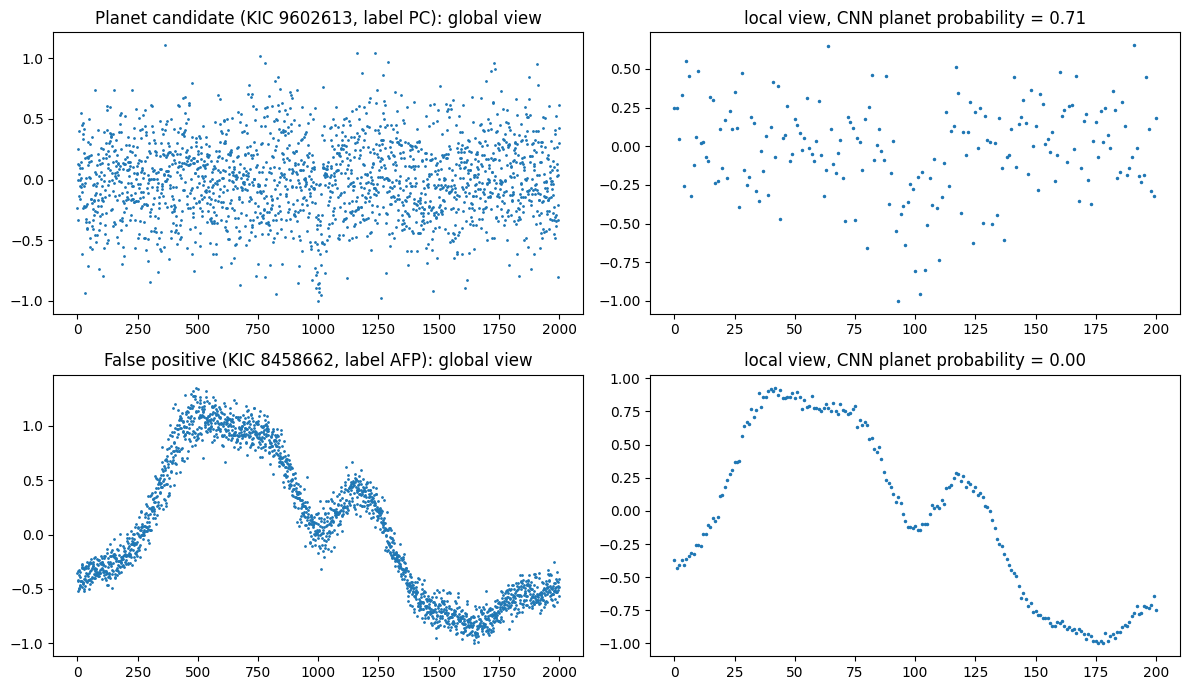

planet index: 135 | false positive index: 120 | its label: AFP


In [10]:
import matplotlib.pyplot as plt

def label_of(i):
    m = big_test[np.isclose(big_test.tce_period, te["P"][i]) &
                 np.isclose(big_test.tce_duration, te["U"][i])]
    return m.iloc[0].av_training_set, int(m.iloc[0].kepid)

order = np.argsort(cnn_probs)
nonplanets = [int(i) for i in order if te["Y"][i] == 0]
planets = [int(i) for i in order[::-1] if te["Y"][i] == 1]

pl = planets[0]
eb = next((i for i in nonplanets[:40] if label_of(i)[0] == "AFP"), nonplanets[0])

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, (idx, name) in enumerate([(pl, "Planet candidate"), (eb, "False positive")]):
    lab, kid = label_of(idx)
    p = cnn_probs[idx]
    axes[row, 0].plot(te["G"][idx], ".", markersize=2)
    axes[row, 0].set_title(f"{name} (KIC {kid}, label {lab}): global view")
    axes[row, 1].plot(te["L"][idx], ".", markersize=3)
    axes[row, 1].set_title(f"local view, CNN planet probability = {p:.2f}")
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/exoplanet/readme_visual.png', dpi=150)
plt.show()
print("planet index:", pl, "| false positive index:", eb, "| its label:", label_of(eb)[0])

In [9]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

url = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query="
       "select+kepid,tce_plnt_num,tce_period,tce_time0bk,tce_duration,tce_depth,av_training_set"
       "+from+q1_q17_dr24_tce&format=csv")
tce = pd.read_csv(url)
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()
tce["planet"] = (tce.av_training_set == "PC").astype(int)

gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
trainval_idx, test_idx = next(gss.split(tce, groups=tce.kepid))
test = tce.iloc[test_idx]

rng = np.random.RandomState(42)
stars = rng.choice(tce.kepid.unique(), size=3000, replace=False)[:1000]
big_test = test[test.kepid.isin(stars)]
print(len(big_test))

186


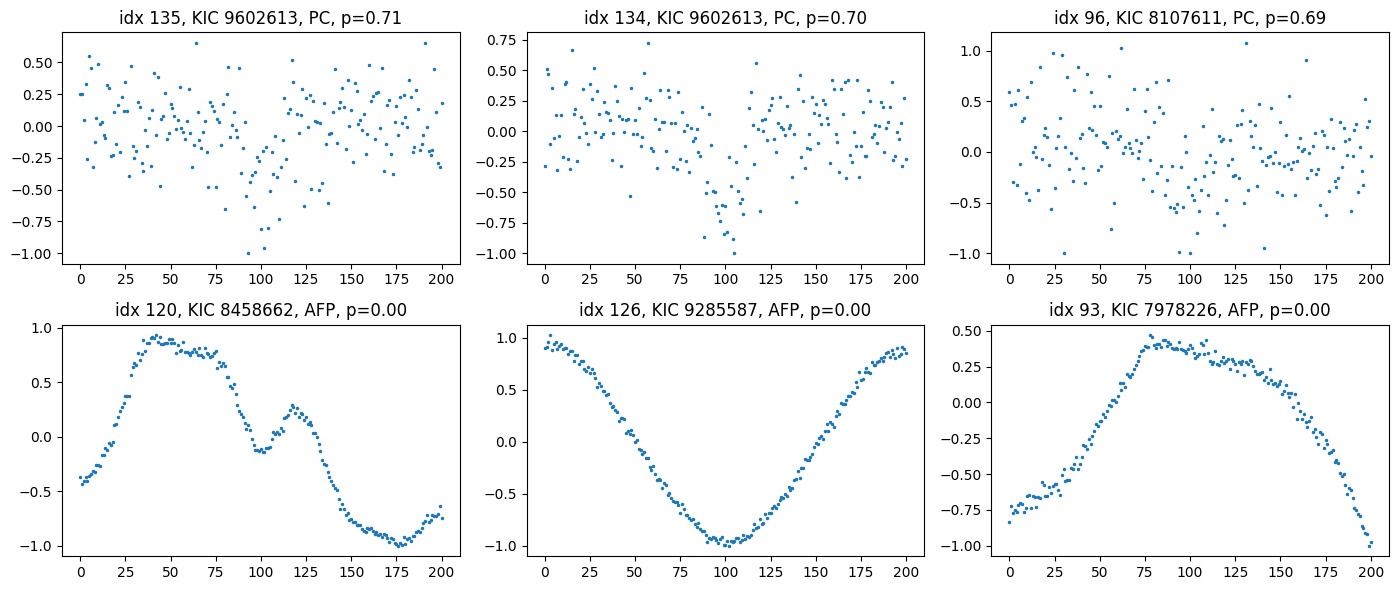

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for k, idx in enumerate(planets[:3]):
    lab, kid = label_of(idx)
    axes[0, k].plot(te["L"][idx], ".", markersize=3)
    axes[0, k].set_title(f"idx {idx}, KIC {kid}, {lab}, p={cnn_probs[idx]:.2f}")
afp = [i for i in nonplanets if label_of(i)[0] == "AFP"][:3]
for k, idx in enumerate(afp):
    lab, kid = label_of(idx)
    axes[1, k].plot(te["L"][idx], ".", markersize=3)
    axes[1, k].set_title(f"idx {idx}, KIC {kid}, {lab}, p={cnn_probs[idx]:.2f}")
plt.tight_layout()
plt.show()

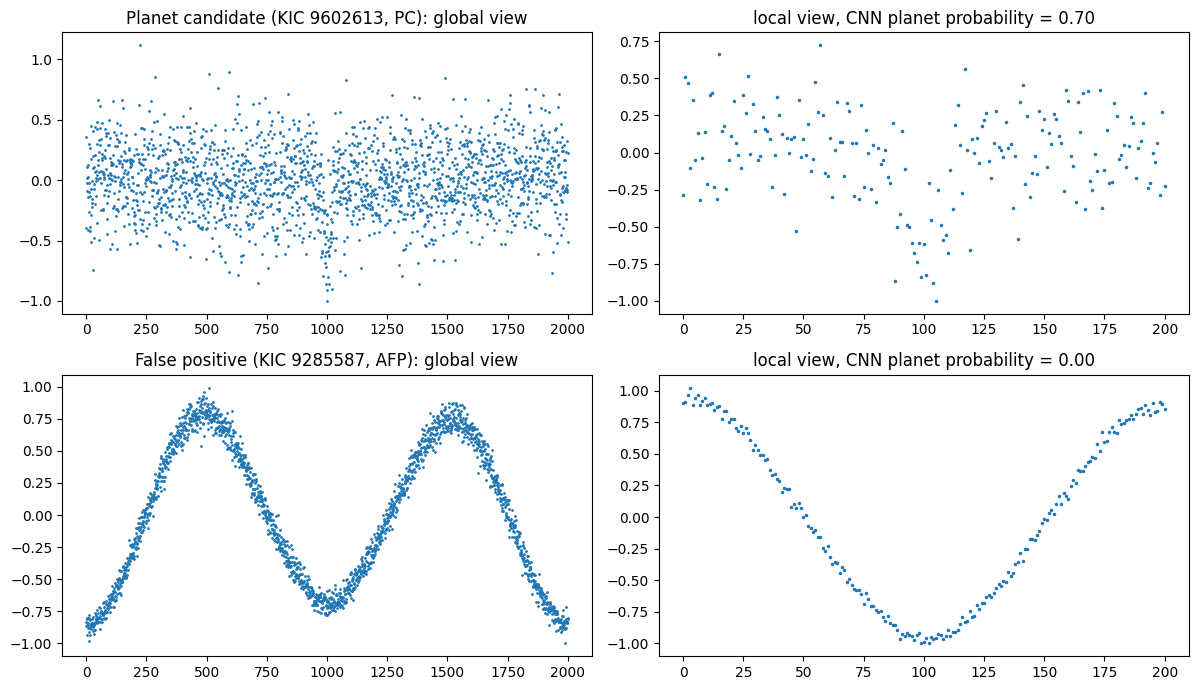

In [12]:
pl, fp = 134, 126

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, (idx, name) in enumerate([(pl, "Planet candidate"), (fp, "False positive")]):
    lab, kid = label_of(idx)
    axes[row, 0].plot(te["G"][idx], ".", markersize=2)
    axes[row, 0].set_title(f"{name} (KIC {kid}, {lab}): global view")
    axes[row, 1].plot(te["L"][idx], ".", markersize=3)
    axes[row, 1].set_title(f"local view, CNN planet probability = {cnn_probs[idx]:.2f}")
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/exoplanet/readme_visual.png', dpi=150)
plt.show()

In [13]:
torch.save(model.state_dict(), '/content/drive/MyDrive/exoplanet/cnn_1000stars.pt')
print("model saved")

model saved
